# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
## Evaluation step - Step 5

**Notebook by Alice DuVivier - April 2026**
- Reads in the top som combos and plot the composite maps

In [1]:
import pandas as pd
from minisom import MiniSom, asymptotic_decay
import xarray as xr
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import seaborn as sns
import pickle
import sammon
import dask

In [2]:
# set path where the som finalist files are
dir_base = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/'

## Section 1: Load data to make composites
- not identical to training data so we can see larger area patterns

In [3]:
# set input directory
dir_in = dir_base + 'data_for_composites/'

In [4]:
# Load data for larger area than only training area - set file name
fin_training = 'psl_autumn_decadal_alaska_cam_grid'
# load data
ds = xr.open_mfdataset(dir_in+fin_training+'.nc')

In [5]:
# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

In [6]:
# need to stack the data in the "time" dimension so that it matches training data - stacking all dates (ntimes = ensemble x decades x autumn days)

# stack all times into a single array
ds_all_times = ds.stack(time=("ensemble","decades","autumn_days"))

In [7]:
# save just psl and convert to hPa from Pa
ds_plot = ds_all_times.psl/100.0

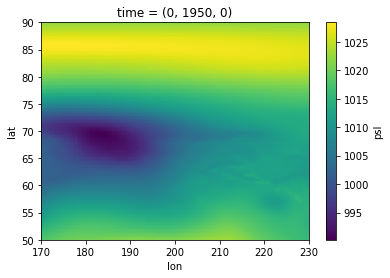

In [8]:
ds_plot.isel(time=0).plot()

## Section 2: Load training data to interpret SOMs

In [9]:
# set input directory
dir_in = dir_base + 'som_training/'

In [10]:
def normalize_data(data):
    """
    Function for normalizing data prior to training using z-score
    """
    return (data - np.nanmean(data)) / np.nanstd(data)

In [11]:
# open file saved in earlier notebook (soms_antarctica-gettingdata.ipynb)
subset = xr.open_dataset(dir_in+'mesaclip_training_data_alaska_psl_autumn_decadal.nc')

# assign to numpy array object
subsetarray = subset['train_data'].values

# set data
data = normalize_data(subsetarray)

# set data input length
input_length = subsetarray.shape[1]    # using preprocessed data array; Number of the elements of the vectors in input.

## Section 3: Set the parameter combinations for SOM finalists
- Manually went through the sammon maps to see what they look like for each size. Have narrowed down pairs, below, based on that assessment.
- Note that the asymmetrical maps didn't have ANY flat sammon maps, so we've eliminated them from further work.
- In addition to setting the rows, columns, rank, we also have to set the "best" parameters from possible winners
    - sigma - spread of neighborhood function
    - lrs - initial learning rate (at the iteration t we have learning_rate(t) = learning_rate / (1 + t/T) where T is #num_iteration/2)
    - niter - how many iterations to go through during training. It is possible to "overtrain"

In [12]:
# set output directory
dir_out = dir_in + '/som_finalists/'

In [13]:
### 3x3 ###
# set paired values for possible winning maps based on Sammon maps evaluation
som_grid_rows    = [3]    # (y-axis)
som_grid_cols    = [3]    # (x-axis)
ranks            = [1, 3, 10, 31, 41]
sigs             = [1.0, 1.0, 1.0, 1.0]
lrs              = [0.005, 0.01, 0.01, 0.005, 0.04]
nitrs            = [1000000, 250000, 100000, 250000, 10000]

### MANUAL CHANGING REQUIRED HERE ##
# select which set to plot
# n = 0-4 (matches sizes set above)
n = 3

In [14]:
### 4x4 ###
## set paired values for possible winning maps based on Sammon maps evaluation
#som_grid_rows    = [4]    # (y-axis)
#som_grid_cols    = [4]    # (x-axis)
#ranks            = [17, 19, 26, 39, 41, 45, 60]
#sigs             = [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0]
#lrs              = [0.05, 0.04, 0.05, 0.005, 0.01, 0.005, 0.05]
#nitrs            = [500000, 500000, 250000, 100000, 50000, 50000, 1000000]

### MANUAL CHANGING REQUIRED HERE ##
## select which set to plot
## n = 0-6 (matches sizes set above)
#n = 6

In [15]:
### 5x5 ###
## set paired values for possible winning maps based on Sammon maps evaluation
#som_grid_rows    = [5]    # (y-axis)
#som_grid_cols    = [5]    # (x-axis)
#ranks            = [58, 61, 69, 90]
#sigs             = [2.0, 2.0, 2.0, 3.0]
#lrs              = [0.01, 0.04, 0.05, 0.5 ]
#nitrs            = [1000000, 500000, 50000, 50000]

### MANUAL CHANGING REQUIRED HERE ##
## select which set to plot
## n = 0-3 (matches sizes set above)
#n = 3

In [16]:
# select info for input file (set above)
som_row = som_grid_rows[0]
som_col = som_grid_cols[0]
rank = ranks[n]
sig = sigs[n]
lr = lrs[n]
n_iter = nitrs[n]

In [17]:
# set the input name file from this
fin = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
print(fin)

# set output file name from this
fout = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_rank_'+str(rank)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
print(fout)

som_alaska_psl_3x3_sig1.0_lr0.005_iter250000
som_alaska_psl_3x3_rank_31_sig1.0_lr0.005_iter250000


## Section 4: Load pickles of "winning" combos and make assessment plots

In [18]:
# open pickle
with open(dir_in+'pickles/'+fin+'.p', 'rb') as infile:
    som = pickle.load(infile)

In [19]:
# double check qerror
qerr = som.quantization_error(data)
print('quantization error: '+str(qerr))

quantization error: 26.452061178363934


## Plot sammon map of lattice

TolFun exceeded: Optimisation terminated


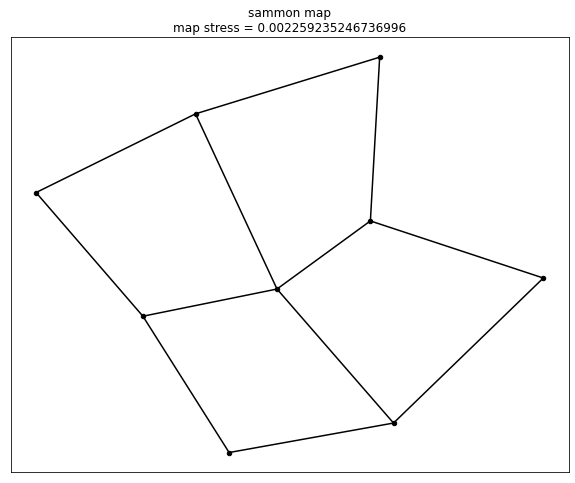

In [20]:
# Calculate sammon coordinates (y) for map and "map stress" (E)
[y,E] = sammon.sammon(som.get_weights().reshape(som_col*som_row, input_length),2,display=1)

# Plot Sammon map nodes
fig = plt.figure(figsize=(10,8))
plt.scatter(y[:,0], y[:,1], s=20, c='black', marker='o')

# Add lines between nodes
tmp = np.reshape(y,(som_col,som_row,2))
len_x, len_y, len_z = tmp.shape
    
# add vertical lines
for i in range(len_x-1):
    for j in range(len_y):
        plt.plot(tmp[i:i+2,j,0],tmp[i:i+2,j,1],c='black')
    
# add horizontal lines
for i in range(len_x):
    for j in range(len_y-1):
        plt.plot(tmp[i,j:j+2,0],tmp[i,j:j+2,1],c='black')  
    
plt.xticks([])
plt.yticks([])
plt.title(r"sammon map" "\n" r"map stress = "+str(E), fontsize=12)
    
# save figure
file_out = dir_out+fout+'_sammon.png'
plt.savefig(file_out, bbox_inches='tight', dpi=200)


## Plot frequencies across lattice

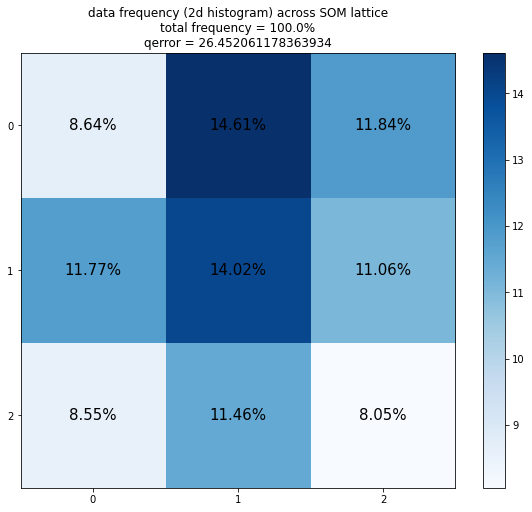

In [21]:
# set frequencies
frequencies = 100.*((som.activation_response(data))/sum(sum(som.activation_response(data))))
#verify the total frequency is 100%
total = sum(sum(frequencies))

# Plot frequencies across SOM lattice
fig = plt.figure(figsize=(10,8))
ax = plt.subplot(111)
im = ax.imshow(frequencies, cmap='Blues')   
    
# Loop over data dimensions and create text annotations in each cell
len_x, len_y = frequencies.shape
for i in range(len_x):
    for j in range(len_y):
        text = ax.text(j, i, str(round(frequencies[i, j],2))+'%', fontsize=15,
                       ha="center", va="center", color="k")

# Make cosmetic changes
cbar = plt.colorbar(im)
plt.title(r"data frequency (2d histogram) across SOM lattice" "\n" r"total frequency = "+str(total)+"%" "\n" r"qerror = "+str(qerr), fontsize=12)
plt.xticks(np.arange(0,som_row, 1))
plt.yticks(np.arange(0,som_col, 1))
    
# save figure
file_out = dir_out+fout+'_freq.png'
plt.savefig(file_out, bbox_inches='tight', dpi=200)


## Plot composite maps of psl anomaly across lattice

### Load SOM info for making composites

In [22]:
# create an empty dictionary using the rows and columns of SOM
keys = [i for i in product(range(som_row),range(som_col))]
winmap = {key: [] for key in keys}

In [23]:
# set frequencies
frequencies = 100.*((som.activation_response(data))/sum(sum(som.activation_response(data))))
#verify the total frequency is 100%
total = sum(sum(frequencies))

# grab the indices for the data within the SOM lattice
for i, x in enumerate(data):
    winmap[som.winner(x)].append(i) 

# create list of the dictionary keys
som_keys = list(winmap.keys())
print(f"Number of composite maps: {len(som_keys)}")
print(f"The rows and columns of the SOM lattice to use to grab SOM indexes:\n{[i for i in list(winmap.keys())]}")

Number of composite maps: 9
The rows and columns of the SOM lattice to use to grab SOM indexes:
[(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2)]


### Set plotting information

In [24]:
## set colors
cmap_choice = plt.cm.get_cmap('coolwarm')

# set lat/lon bounds
lat_max = 80
lat_min = 50
lon_max = 230
lon_min = 170
lon_avg = 200

# set plotting info
title = 'PSL'
units = 'hPa'
vmin_in = 980 #960
vmax_in = 1040 #1060
ticks_1 = np.arange(vmin_in,vmax_in,10)
#ticks_1 = [0,0.25,0.5,0.75,1.0,1.25,1.5,1.75] #np.arange(vmin_in,vmax_in,0.2)

4271


/glade/work/duvivier/miniconda3/envs/antarctica_som_env/lib/python3.7/site-packages/cartopy/mpl/geoaxes.py:1763: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  result = matplotlib.axes.Axes.pcolor(self, *args, **kwargs)


7219


/glade/work/duvivier/miniconda3/envs/antarctica_som_env/lib/python3.7/site-packages/cartopy/mpl/geoaxes.py:1763: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  result = matplotlib.axes.Axes.pcolor(self, *args, **kwargs)


5852


...

/glade/work/duvivier/miniconda3/envs/antarctica_som_env/lib/python3.7/site-packages/cartopy/mpl/geoaxes.py:1763: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  result = matplotlib.axes.Axes.pcolor(self, *args, **kwargs)


5662


/glade/work/duvivier/miniconda3/envs/antarctica_som_env/lib/python3.7/site-packages/cartopy/mpl/geoaxes.py:1763: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  result = matplotlib.axes.Axes.pcolor(self, *args, **kwargs)


3978


/glade/work/duvivier/miniconda3/envs/antarctica_som_env/lib/python3.7/site-packages/cartopy/mpl/geoaxes.py:1763: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  result = matplotlib.axes.Axes.pcolor(self, *args, **kwargs)


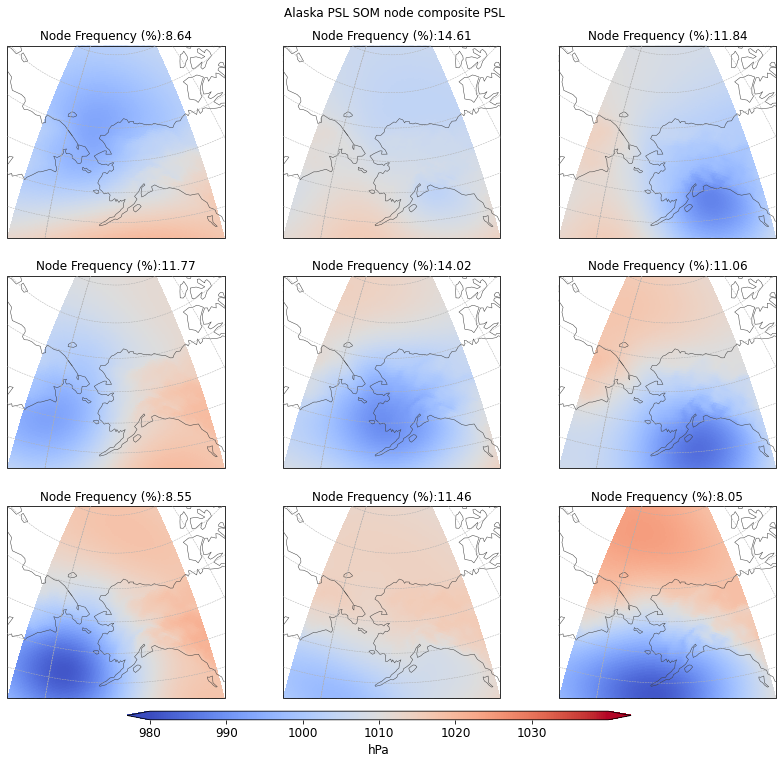

In [25]:
# set some of the plot info
fig, axs = plt.subplots(som_row, som_col, subplot_kw={'projection':ccrs.Stereographic(central_longitude=lon_avg)}, figsize=(14,12))
    
# loop through the different maps to get the indices of training data that map there
for map_num in range(len(som_keys)):
    # get indices of training data that mapped to this node
    inds = winmap[som_keys[map_num]]
    print(len(inds))
    # grab the compositing data that corresponds to those training times
    with dask.config.set(**{'array.slicing.split_large_chunks': False}):
        ds_sub = ds_plot.isel(time=inds)          
    ds_sub = ds_sub.mean(dim="time", skipna=True)
        
    # make plot for this node - note using .values converts from xarray to numpy array
    cs = axs[som_keys[map_num][0],som_keys[map_num][1]].pcolor(ds_plot.coords['lon'].values, 
                                                               ds_plot.coords['lat'].values, 
                                                               ds_sub.values, 
                                                               vmin=vmin_in, vmax=vmax_in, cmap=cmap_choice,
                                                               transform=ccrs.PlateCarree())
        
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_extent([lon_min,lon_max,lat_min,lat_max])
    axs[som_keys[map_num][0],som_keys[map_num][1]].coastlines(resolution='110m', color='0.25', linewidth=0.5, zorder=10)
    #axs[som_keys[map_num][0],som_keys[map_num][1]].add_feature(cartopy.feature.LAND, zorder=10, edgecolor='k', facecolor='w')    
    axs[som_keys[map_num][0],som_keys[map_num][1]].gridlines(linestyle='--', linewidth=0.5, zorder=11)
    
    # plot titles
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_title('Node Frequency (%):{:.2f}'.format(frequencies.flatten()[map_num]), fontsize=12)
    
# finalize figure 
plt.suptitle('Alaska PSL SOM node composite '+title, fontsize=12, x=0.515, y=0.925)

# colorbar stuff
cbar_ax = fig.add_axes([0.25,0.1,0.5,0.01]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_1[:],
                    orientation='horizontal', extend='both')
cbar.ax.set_xticklabels(list(ticks_1))
cbar.ax.tick_params(labelsize=12)
cbar.set_label(units, fontsize=12)
    
# save figure
file_out = dir_out+fout+'_composite.png'
plt.savefig(file_out, bbox_inches='tight', dpi=200)
